# Chapter 7 — Support Vector Machines and Kernel Methods

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

*Support Vector Machine* (SVM) adalah salah satu algoritma klasifikasi dan regresi paling elegan secara matematis: alih-alih sekadar mencari batas yang memisahkan kelas, SVM mencari batas dengan **margin terbesar**, yaitu jarak terlebar antara batas keputusan dan titik-titik terdekat dari tiap kelas (*support vectors*). Dengan **kernel trick**, SVM dapat membentuk batas keputusan non-linear tanpa pernah menghitung transformasi fitur berdimensi tinggi secara eksplisit. Chapter ini membahas dasar SVM untuk klasifikasi (`SVC`) dan regresi (`SVR`), berbagai fungsi kernel, *tuning* hiperparameter $C$, `kernel`, `degree`, perilaku SVM pada data berdimensi tinggi (*wide data*), serta evaluasi model dengan *classification report* dan kurva ROC.

**Daftar Isi**

1. 7.1 Pengantar Support Vector Machines
2. 7.2 Fungsi Kernel dan Penerapannya
3. 7.3 Tuning Parameter SVM
4. 7.4 SVM pada Ruang Berdimensi Tinggi
5. 7.5 Evaluasi Model SVM
6. Latihan (Exercise 1–3: SVM sederhana, Grid Search, Visualisasi Decision Boundary)
7. Ringkasan Chapter 7

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 7 (urutan resep sama dengan notebook resmi Packt), dengan sedikit penyesuaian agar berjalan di scikit-learn 1.9 dan lebih jelas, lalu menjelaskan teori di balik setiap resep (bagian **Teori:**) dan menafsirkan hasil eksekusinya (bagian **Interpretasi:**). Semua dataset berasal dari modul `sklearn.datasets` (Iris, Breast Cancer, dan data sintetis `make_classification`).

## Import Library

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_iris, load_breast_cancer, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC, SVR
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             mean_squared_error, r2_score, roc_curve, auc)
from IPython.display import display

# Pengaturan tampilan gambar agar ukurannya moderat
plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')

print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)

numpy        : 2.5.4
pandas       : 3.1.0
scikit-learn : 1.9.1


In [2]:
def style_report(report_df):
    """Mewarnai tabel classification report (sama seperti gaya notebook resmi)."""
    return (report_df
        .style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}',
                 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

## 7.1 Pengantar Support Vector Machines

**Teori:**

**Hyperplane dan margin.** Untuk klasifikasi biner dengan label $y_i\in\{-1,+1\}$, classifier linear memprediksi $\hat y = \operatorname{sign}(f(\mathbf x))$ dengan $f(\mathbf x)=\mathbf w^\top\mathbf x + b$. Himpunan $\{\mathbf x: f(\mathbf x)=0\}$ adalah *hyperplane* pemisah. Jarak (bertanda) titik $\mathbf x_i$ ke hyperplane adalah $y_i f(\mathbf x_i)/\lVert\mathbf w\rVert$. Bila data dapat dipisahkan, ada tak hingga hyperplane yang memisahkan; SVM memilih yang **margin**-nya terbesar. Dengan menormalkan skala sehingga titik terdekat memenuhi $y_i f(\mathbf x_i)=1$, lebar margin menjadi $2/\lVert\mathbf w\rVert$, sehingga memaksimalkan margin setara dengan

$$
\min_{\mathbf w,b}\ \tfrac12\lVert\mathbf w\rVert^2 \quad\text{s.t.}\quad y_i(\mathbf w^\top\mathbf x_i+b)\ge 1,\ i=1,\dots,n \qquad\text{(hard margin)}.
$$

**Soft margin.** Data nyata jarang terpisah sempurna. Variabel *slack* $\xi_i\ge0$ mengizinkan pelanggaran margin, dibayar dengan penalti $C$:

$$
\min_{\mathbf w,b,\boldsymbol\xi}\ \tfrac12\lVert\mathbf w\rVert^2 + C\sum_{i=1}^n \xi_i \quad\text{s.t.}\quad y_i(\mathbf w^\top\mathbf x_i+b)\ge 1-\xi_i,\ \xi_i\ge 0 .
$$

Ini ekuivalen dengan meminimalkan **hinge loss** $\sum_i \max(0,\,1-y_i f(\mathbf x_i))$ ditambah regularisasi L2 $\tfrac{1}{2C}\lVert\mathbf w\rVert^2$. Jadi $C$ adalah kebalikan kekuatan regularisasi: $C$ kecil → margin lebar, lebih banyak pelanggaran ditoleransi (bias tinggi, varians rendah); $C$ besar → model berusaha mengklasifikasikan semua titik latih dengan benar (rawan *overfitting*).

**Bentuk dual dan support vectors.** Dengan pengali Lagrange $\alpha_i$, solusi optimal berbentuk $\mathbf w=\sum_i \alpha_i y_i \mathbf x_i$ dengan $0\le\alpha_i\le C$. Masalah dualnya

$$
\max_{\boldsymbol\alpha}\ \sum_i\alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_j y_i y_j\,\mathbf x_i^\top\mathbf x_j \quad\text{s.t.}\quad 0\le\alpha_i\le C,\ \textstyle\sum_i\alpha_i y_i=0 .
$$

Kondisi KKT membuat sebagian besar $\alpha_i=0$; hanya titik yang berada **di atau di dalam margin** (atau salah klasifikasi) yang memiliki $\alpha_i>0$. Titik-titik inilah **support vectors**: batas keputusan hanya bergantung pada mereka, sehingga $f(\mathbf x)=\sum_{i\in SV}\alpha_i y_i\,\mathbf x_i^\top\mathbf x + b$. Data dual hanya muncul sebagai hasil kali dalam $\mathbf x_i^\top\mathbf x_j$, dan inilah pintu masuk *kernel trick* (resep 7.2).

**Multikelas.** `SVC` (berbasis *libsvm*) menangani $K$ kelas dengan skema **one-vs-one**: melatih $K(K-1)/2$ classifier biner lalu melakukan voting. Pada Iris ($K=3$) ada 3 classifier biner.

**Support Vector Regression (SVR).** SVR memakai **$\varepsilon$-insensitive loss**: galat dengan $|y_i-f(\mathbf x_i)|\le\varepsilon$ tidak dihukum sama sekali (sebuah "tabung" selebar $2\varepsilon$ di sekitar fungsi), di luar itu dihukum linear:

$$
\min_{\mathbf w,b}\ \tfrac12\lVert\mathbf w\rVert^2 + C\sum_i \max\bigl(0,\ |y_i-f(\mathbf x_i)|-\varepsilon\bigr).
$$

Hanya titik di luar/di tepi tabung yang menjadi support vectors. Default scikit-learn: `kernel='rbf'`, `C=1.0`, `epsilon=0.1`.

**Kapan dipakai & jebakan.** SVM bekerja baik untuk data berukuran kecil–menengah, dimensi tinggi, dan batas keputusan yang kompleks. Kelemahannya: (1) **sensitif terhadap skala fitur** karena margin diukur dengan jarak Euclidean, sehingga hampir selalu perlu `StandardScaler`; (2) biaya pelatihan *kernel SVM* sekitar $O(n^2)$–$O(n^3)$, berat untuk ratusan ribu sampel (pakai `LinearSVC`/`SGDClassifier`); (3) keluaran aslinya adalah skor jarak, bukan probabilitas.

Pada resep ini, `SVC(kernel='linear')` dilatih pada Iris (4 fitur, 3 kelas), lalu `SVR` dipakai untuk "regresi" label kelas Iris dari dua fitur pertama, sebuah contoh ilustratif dari buku (label kelas sebenarnya kategorikal, jadi ini bukan pemakaian SVR yang ideal).

In [3]:
# Memuat dataset Iris
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Membagi data latih/uji (70:30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Ukuran X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Distribusi kelas uji:', np.bincount(y_test))

Ukuran X_train: (105, 4) | X_test: (45, 4)
Distribusi kelas uji: [18 12 15]


In [4]:
# SVM linear untuk klasifikasi
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(X_train, y_train)

# Prediksi dan evaluasi
y_pred = svm_classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

print(f"Accuracy: {accuracy:.2f}")
# Informasi tambahan: banyaknya support vector per kelas
print('Jumlah support vector per kelas:', svm_classifier.n_support_,
      '| total:', svm_classifier.n_support_.sum(), 'dari', len(X_train), 'titik latih')
display(style_report(report_df))

Accuracy: 0.93
Jumlah support vector per kelas: [ 3 10  8] | total: 21 dari 105 titik latih


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


**Interpretasi:**

- SVC kernel linear mencapai akurasi uji **0.93** (42 dari 45 benar). Kelas 0 (*setosa*) diklasifikasikan sempurna (precision = recall = 1.000), sesuai fakta bahwa *setosa* terpisah secara linear dari dua kelas lain.
- Semua kesalahan terjadi di antara kelas 1 (*versicolor*, recall 0.833: 2 dari 12 meleset) dan kelas 2 (*virginica*, recall 0.933: 1 dari 15 meleset). Kedua spesies ini memang tumpang tindih di ruang fitur.
- Hanya **21 dari 105** titik latih yang menjadi support vector (3 untuk *setosa*, 10 dan 8 untuk dua kelas lain). Ini menunjukkan sifat *sparse* SVM: batas keputusan ditentukan oleh sedikit titik di sekitar margin, dan kelas yang mudah dipisahkan (*setosa*) hanya membutuhkan 3 titik.

In [5]:
# SVR (kernel RBF) memakai dua fitur pertama (sepal length & sepal width)
svm_regressor = SVR(kernel='rbf')
svm_regressor.fit(X_train[:, :2], y_train)

# Prediksi dan evaluasi (untuk regresi dipakai MSE / R-squared)
y_pred_reg = svm_regressor.predict(X_test[:, :2])
mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")
print(f"R-squared: {r2_score(y_test, y_pred_reg):.2f}")
print('Jumlah support vector SVR:', len(svm_regressor.support_), 'dari', len(X_train))

MSE: 0.20
R-squared: 0.72
Jumlah support vector SVR: 70 dari 105


**Interpretasi:**

- SVR (RBF) yang memprediksi label 0/1/2 dari *sepal length* dan *sepal width* memperoleh **MSE 0.20** dan $R^2$ **0.72**: prediksi rata-rata meleset sekitar $\sqrt{0.20}\approx0.45$ unit label. Hasil ini wajar karena dua fitur sepal saja tidak cukup memisahkan *versicolor* dan *virginica*.
- Sebanyak **70 dari 105** titik latih menjadi support vector. Dengan $\varepsilon=0.1$ (tabung sempit) dan target yang hanya bernilai 0, 1, 2, sebagian besar titik berada di luar tabung sehingga ikut menentukan fungsi.
- Ingat bahwa ini hanya ilustrasi dari buku: memperlakukan label kategorikal sebagai angka kontinu mengasumsikan urutan dan jarak antar-kelas (0→1→2) yang sebenarnya tidak ada. Untuk masalah klasifikasi gunakan `SVC`.

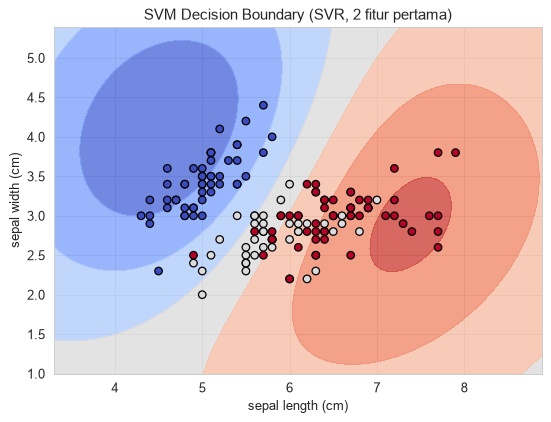

In [6]:
# Visualisasi permukaan prediksi SVR pada dua fitur pertama
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Hanya dua kolom pertama yang dipakai model (SVR dilatih dengan 2 fitur)
grid_points = np.c_[xx.ravel(), yy.ravel()]

fig, ax = plt.subplots(figsize=(7, 5))
disp = DecisionBoundaryDisplay.from_estimator(
    svm_regressor,
    grid_points,
    response_method="predict",
    plot_method="contourf",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    ax=ax
)
ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap=plt.cm.coolwarm)
ax.set_title("SVM Decision Boundary (SVR, 2 fitur pertama)")
ax.set_xlabel(feature_names[0])
ax.set_ylabel(feature_names[1])
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
plt.show()

**Interpretasi:**

- Karena modelnya regresi, plot ini tidak menunjukkan batas tegas antar-kelas. Yang terlihat adalah **permukaan prediksi kontinu**: biru tua (≈0, *setosa*) di kiri atas (sepal pendek dan lebar), merah (≈2, *virginica*) di kanan bawah (sepal panjang), dan zona abu-abu (≈1, *versicolor*) di antaranya.
- Bentuk kontur yang membulat/elips mencerminkan kernel RBF, yaitu jumlah "gundukan" Gaussian di sekitar support vector. Jauh dari data (pojok kiri bawah dan kanan atas), prediksi kembali ke nilai tengah (≈1) karena pengaruh kernel RBF meluruh terhadap jarak, sehingga SVR mendekati nilai intersep $b$.
- Titik putih (*versicolor*) dan merah (*virginica*) bercampur di area sepal length 5.5–7, menjelaskan mengapa MSE tidak bisa mendekati nol dengan dua fitur ini.
- Perbedaan dari kode buku: buku membuat `grid_points` 4 kolom lalu memotongnya kembali menjadi 2 kolom. Di sini langsung dibuat 2 kolom karena `svm_regressor` memang dilatih dengan 2 fitur; hasilnya sama.

## 7.2 Fungsi Kernel dan Penerapannya

**Teori:**

**Feature map dan kernel trick.** Untuk membuat batas non-linear, data dapat dipetakan ke ruang fitur baru $\phi:\mathbb R^p\to\mathcal H$ lalu SVM linear dijalankan di $\mathcal H$. Karena bentuk dual hanya membutuhkan hasil kali dalam, kita cukup mendefinisikan **fungsi kernel**

$$
K(\mathbf x,\mathbf x') = \langle\phi(\mathbf x),\phi(\mathbf x')\rangle_{\mathcal H}
$$

tanpa pernah menghitung $\phi$ secara eksplisit. Fungsi keputusan menjadi $f(\mathbf x)=\sum_{i\in SV}\alpha_i y_i K(\mathbf x_i,\mathbf x)+b$. Contoh: untuk $\mathbf x\in\mathbb R^2$, $K(\mathbf x,\mathbf x')=(\mathbf x^\top\mathbf x')^2$ setara dengan $\phi(\mathbf x)=(x_1^2,\sqrt2 x_1x_2,x_2^2)$, tetapi menghitung $K$ jauh lebih murah daripada membentuk $\phi$, terlebih untuk derajat tinggi. Sebuah fungsi sah sebagai kernel bila matriks Gram $[K(\mathbf x_i,\mathbf x_j)]$ selalu **semi-definit positif** (teorema Mercer).

**Kernel yang tersedia di `SVC`:**

| Kernel | Rumus $K(\mathbf x,\mathbf x')$ | Parameter |
|---|---|---|
| `linear` | $\mathbf x^\top\mathbf x'$ | — |
| `poly` | $(\gamma\,\mathbf x^\top\mathbf x' + r)^d$ | `degree`=$d$ (default 3), `gamma`, `coef0`=$r$ (default 0) |
| `rbf` (Gaussian) | $\exp(-\gamma\lVert\mathbf x-\mathbf x'\rVert^2)$ | `gamma` |
| `sigmoid` | $\tanh(\gamma\,\mathbf x^\top\mathbf x' + r)$ | `gamma`, `coef0` |

Default `gamma='scale'` berarti $\gamma = 1/(p\cdot\operatorname{Var}(X))$, sehingga kernel otomatis menyesuaikan skala data secara global (tetapi tidak menyamakan skala antar-fitur).

**Intuisi RBF.** Kernel RBF mengukur kemiripan yang meluruh secara eksponensial terhadap jarak; ruang fiturnya berdimensi tak hingga. $\gamma$ adalah kebalikan "jangkauan pengaruh" tiap support vector: $\gamma$ kecil → batas halus (mendekati linear), $\gamma$ besar → setiap titik punya pengaruh sangat lokal sehingga batas menjadi berliku dan mudah *overfitting*. $C$ dan $\gamma$ saling berinteraksi sehingga sebaiknya di-*tune* bersama.

**Memilih kernel.** Mulailah dari `linear` bila jumlah fitur besar atau data teks/sparse (seringkali sudah cukup terpisah secara linear dan paling cepat). `rbf` adalah default yang kuat untuk data tabular berdimensi rendah–menengah. `poly` berguna bila interaksi fitur berderajat tertentu bermakna, namun dengan `coef0=0` kernel polinomial hanya memuat suku berderajat **tepat** $d$ dan bisa tidak stabil secara numerik untuk $d$ besar.

Pada resep ini kernel polinomial (derajat 3) dan RBF dibandingkan pada Iris, lalu batas keputusan ketiga kernel divisualisasikan memakai dua fitur pertama (*sepal length*, *sepal width*).

In [7]:
# Kernel polinomial derajat 3 (Iris, 4 fitur)
svm_poly = SVC(kernel='poly', degree=3)
svm_poly.fit(X_train, y_train)
y_pred_poly = svm_poly.predict(X_test)

accuracy_poly = accuracy_score(y_test, y_pred_poly)
report_df_poly = pd.DataFrame(classification_report(y_test, y_pred_poly, output_dict=True)).transpose()
print(f"Polynomial Kernel Accuracy: {accuracy_poly:.2f}")
display(style_report(report_df_poly))

Polynomial Kernel Accuracy: 0.96


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,1.000,0.833,0.909,12
2,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


In [8]:
# Kernel RBF
svm_rbf = SVC(kernel='rbf')
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
report_df_rbf = pd.DataFrame(classification_report(y_test, y_pred_rbf, output_dict=True)).transpose()
print(f"RBF Kernel Accuracy: {accuracy_rbf:.2f}")
display(style_report(report_df_rbf))

# Ringkasan banyaknya support vector tiap kernel (4 fitur)
print('Total support vector -> linear:', svm_classifier.n_support_.sum(),
      '| poly:', svm_poly.n_support_.sum(), '| rbf:', svm_rbf.n_support_.sum())

RBF Kernel Accuracy: 0.91


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.786,0.917,0.846,12
2,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


Total support vector -> linear: 21 | poly: 14 | rbf: 48


**Interpretasi:**

- Dengan 4 fitur, akurasi uji: **linear 0.93**, **polinomial (d=3) 0.96**, **RBF 0.91**. Ketiganya tetap sempurna untuk *setosa*; perbedaannya hanya pada 1–2 sampel *versicolor*/*virginica*. Polinomial hanya salah pada 2 *versicolor* (precision kelas 1 = 1.000, recall 0.833), sedangkan RBF salah pada 4 sampel (recall *virginica* turun ke 0.800).
- Data uji hanya 45 sampel, sehingga satu sampel setara ±2.2 poin persen. Selisih 0.91 vs 0.96 (2 sampel) **tidak** cukup untuk menyimpulkan kernel mana yang lebih baik; untuk itu perlu validasi silang (resep 7.3).
- Jumlah support vector: linear 21, polinomial 14, RBF **48**. Dengan `gamma='scale'` dan $C=1$, kernel RBF memakai banyak titik untuk membentuk batas yang lebih lokal; batas yang lebih kompleks tidak otomatis memberi akurasi lebih baik pada data sekecil ini.

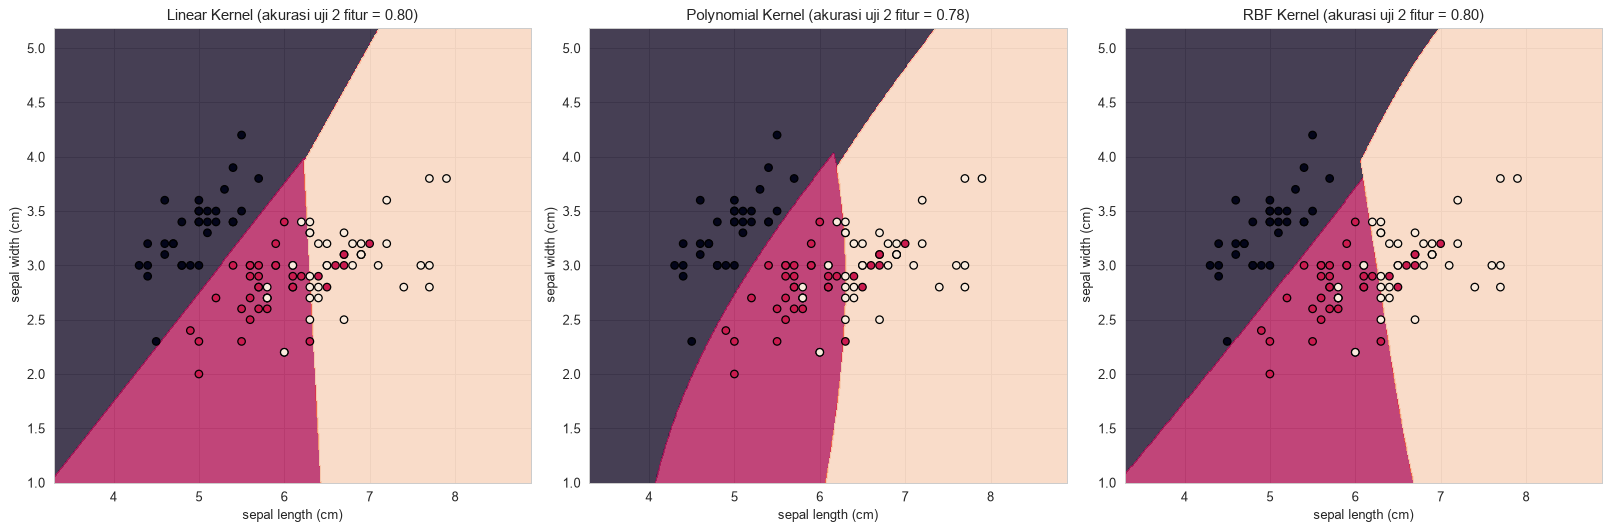

In [9]:
# Mesh grid hanya untuk dua fitur pertama
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

X_train_2d = X_train[:, :2]
X_test_2d = X_test[:, :2]

# Melatih ulang ketiga kernel hanya dengan dua fitur
svm_linear_2d = SVC(kernel='linear').fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf').fit(X_train_2d, y_train)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, model, title in zip(axes, [svm_linear_2d, svm_poly_2d, svm_rbf_2d],
                            ['Linear Kernel', 'Polynomial Kernel', 'RBF Kernel']):
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.8)
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
    ax.set_title(f"{title} (akurasi uji 2 fitur = {model.score(X_test_2d, y_test):.2f})")
    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])
plt.tight_layout()
plt.show()

**Interpretasi:**

- Dengan hanya dua fitur sepal, ketiga kernel menghasilkan batas yang mirip: *setosa* (hitam, kiri atas) terpisah rapi, sedangkan *versicolor* (merah) dan *virginica* (putih) bertumpuk di sekitar sepal length 5.5–7 sehingga akurasi uji turun menjadi **0.80 / 0.78 / 0.80** (linear / poly / RBF) dibanding 0.91–0.96 dengan 4 fitur. Fitur petal ternyata berperan besar dalam memisahkan kedua spesies ini.
- **Linear**: semua batas berupa garis lurus (hasil voting tiga classifier one-vs-one). **Polinomial**: batas melengkung halus, misalnya batas *setosa*/*versicolor* yang membengkok di kiri bawah. **RBF**: batasnya tampak hampir linear di area data, karena `gamma='scale'` memberi jangkauan kernel cukup luas sehingga permukaan yang dihasilkan halus.
- Pelajaran: kernel non-linear tidak dapat "menciptakan" informasi yang tidak ada di fitur. Bila kelas memang tumpang tindih, batas sefleksibel apa pun hanya akan *overfit*.

## 7.3 Tuning Parameter SVM

**Teori:**

**Hiperparameter utama SVC.**

- **$C$** (regularisasi): mengatur *trade-off* antara margin lebar dan kesalahan pada data latih. $C\to\infty$ mendekati *hard margin*; $C$ kecil membiarkan banyak titik masuk ke margin (lebih banyak support vector, model lebih halus).
- **`kernel`** dan parameternya: `degree` (hanya berpengaruh untuk `poly`), `gamma` (untuk `rbf`, `poly`, `sigmoid`), `coef0` (`poly`, `sigmoid`).

**Grid search + cross-validation.** `GridSearchCV` mengevaluasi **setiap kombinasi** dalam grid memakai $k$-fold CV pada data latih: data dibagi menjadi $k$ bagian, model dilatih pada $k-1$ bagian dan dinilai pada bagian sisanya, lalu skor dirata-rata:

$$
\text{CV}(\theta) = \frac1k\sum_{j=1}^{k} \text{Acc}\bigl(\hat f_{\theta}^{(-j)},\ \text{fold}_j\bigr), \qquad \hat\theta=\arg\max_\theta \text{CV}(\theta).
$$

Untuk klasifikasi, `cv=5` otomatis memakai `StratifiedKFold` sehingga proporsi kelas tiap fold terjaga. Setelah pencarian, `refit=True` (default) melatih ulang model terbaik pada seluruh data latih dan menyimpannya di `best_estimator_`; buku melatih ulang secara manual dengan `SVC(**best_params)`, hasilnya sama.

**Hal yang perlu diperhatikan.**

1. Grid buku `{'C':[0.1,1,10], 'kernel':[...], 'degree':[2,3,4]}` menghasilkan 27 kombinasi, padahal `degree` diabaikan oleh kernel `linear` dan `rbf`, sehingga banyak kombinasi sebenarnya identik. Grid yang lebih efisien memakai **daftar grid** (mis. `[{'kernel':['rbf'], 'C':..., 'gamma':...}, {'kernel':['poly'], 'degree':...}]`).
2. Bila skor CV seri, `GridSearchCV` memilih kombinasi yang **pertama** muncul dalam urutan grid (peringkat terkecil), bukan yang paling sederhana.
3. Rentang $C$ dan $\gamma$ sebaiknya dicari dalam **skala logaritmik** (`np.logspace`) karena efeknya bersifat multiplikatif.
4. Skor CV terbaik bersifat sedikit optimistis (dipilih dari banyak kandidat), sehingga performa akhir harus dilaporkan pada data uji yang tidak ikut dipakai saat *tuning*.
5. Bila ada *preprocessing* (mis. scaling), masukkan ke dalam `Pipeline` agar tidak terjadi *data leakage* antar-fold.

In [10]:
# Grid hiperparameter dari buku
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.2f}")

# Melatih ulang model dengan hiperparameter terbaik
best_model = SVC(**best_params)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()
print(f"Accuracy: {accuracy:.2f}")
display(style_report(report_df))

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99
Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


In [11]:
# Tambahan: 10 kombinasi teratas menurut skor CV (perhatikan banyaknya skor seri)
cv_res = pd.DataFrame(grid_search.cv_results_)
cols = ['param_kernel', 'param_C', 'param_degree', 'mean_test_score', 'std_test_score', 'rank_test_score']
display(cv_res[cols].sort_values(['rank_test_score', 'param_kernel']).head(10).round(3))

,param_kernel,param_C,param_degree,mean_test_score,std_test_score,rank_test_score
9,linear,1.0,2,0.990,0.019,1
12,linear,1.0,3,0.990,0.019,1
15,linear,1.0,4,0.990,0.019,1
8,poly,0.1,4,0.990,0.019,1
11,poly,1.0,2,0.990,0.019,1
19,rbf,10.0,2,0.990,0.019,1
22,rbf,10.0,3,0.990,0.019,1
25,rbf,10.0,4,0.990,0.019,1
5,poly,0.1,3,0.981,0.023,9
14,poly,1.0,3,0.981,0.023,9


**Interpretasi:**

- Grid search memilih `{'C': 0.1, 'degree': 4, 'kernel': 'poly'}` dengan skor CV **0.99**. Akurasi ujinya **0.93**, dan *classification report*-nya persis sama dengan SVC linear pada resep 7.1 (salah pada 3 sampel yang sama).
- Tabel 10 teratas memperlihatkan bahwa **8 kombinasi seri** di skor CV 0.990 (±0.019): linear $C=1$ (tiga kali, karena `degree` diabaikan), poly $C=0.1,d=4$, poly $C=1,d=2$, dan RBF $C=10$ (tiga kali). Pada kondisi seri, `GridSearchCV` memilih kombinasi yang muncul paling awal dalam urutan grid, sehingga pilihan "poly derajat 4" sebenarnya hanyalah kebetulan urutan, bukan bukti bahwa kernel ini lebih baik.
- Selisih skor CV (0.99) dan akurasi uji (0.93) menggambarkan dua hal: skor CV terbaik bersifat optimistis karena dipilih dari 27 kandidat, dan data uji 45 sampel sangat bervariasi (3 kesalahan sudah menurunkan akurasi 6.7 poin).

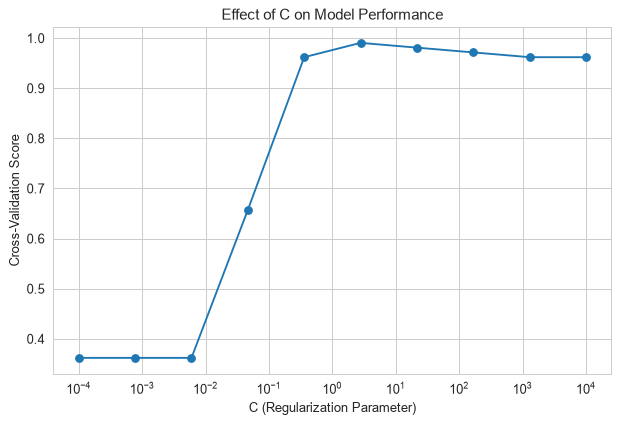

         C  mean_cv_score
    0.0001         0.3619
    0.0008         0.3619
    0.0060         0.3619
    0.0464         0.6571
    0.3594         0.9619
    2.7826         0.9905
   21.5443         0.9810
  166.8101         0.9714
 1291.5497         0.9619
10000.0000         0.9619


In [12]:
# Pengaruh C (skala log) pada kernel RBF
param_grid_c = {
    'C': np.logspace(-4, 4, 10),
    'kernel': ['rbf']
}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.plot(grid_search_c.param_grid['C'], grid_search_c.cv_results_['mean_test_score'], marker='o')
plt.xscale('log')
plt.xlabel('C (Regularization Parameter)')
plt.ylabel('Cross-Validation Score')
plt.title('Effect of C on Model Performance')
plt.show()

print(pd.DataFrame({'C': grid_search_c.param_grid['C'],
                    'mean_cv_score': grid_search_c.cv_results_['mean_test_score']}).round(4).to_string(index=False))

**Interpretasi:**

- Kurva memperlihatkan pola *underfitting → optimum → overfitting* yang klasik:
  - $C\le 0.006$: skor CV **0.362**, sama dengan proporsi kelas terbanyak di data latih (38/105). Regularisasi sangat kuat membuat model praktis selalu menebak kelas mayoritas.
  - $C=0.046$ → 0.657 dan $C=0.36$ → 0.962: model mulai mempelajari struktur data.
  - Puncak di **$C\approx2.78$ dengan skor 0.990**.
  - $C$ lebih besar (21.5 → 0.981, 167 → 0.971, ≥1292 → 0.962): model memaksa setiap titik latih terklasifikasi benar sehingga batas menjadi terlalu rumit dan skor CV turun perlahan.
- Kurva cukup datar di rentang $C\in[0.4, 10^4]$ (0.96–0.99): pada Iris, SVM RBF tidak terlalu sensitif terhadap $C$ selama tidak terlalu kecil. Pencarian berskala log (`np.logspace`) penting untuk menemukan daerah ini dengan sedikit kandidat.

## 7.4 SVM pada Ruang Berdimensi Tinggi

**Teori:**

**Data "lebar" (*wide data*).** Ketika jumlah fitur $p$ sebanding atau melebihi jumlah sampel $n$, banyak model (misalnya OLS) menjadi tidak stabil. SVM relatif tahan terhadap kondisi ini karena:

1. **Kapasitas dikendalikan oleh margin, bukan oleh dimensi.** Teori VC untuk *large-margin classifier* menyatakan dimensi VC dibatasi oleh $\min\bigl(\lceil R^2/\rho^2\rceil,\,p\bigr)+1$, dengan $R$ jari-jari bola yang memuat data dan $\rho$ margin. Margin besar → kapasitas efektif kecil, walaupun $p$ besar.
2. **Solusi hanya bergantung pada support vectors** dan pada matriks Gram $n\times n$, sehingga biaya bergantung pada $n$, bukan langsung pada $p$ (selain menghitung hasil kali dalam, $O(p)$ per pasangan).
3. **Pada dimensi tinggi data cenderung terpisah secara linear** (teorema Cover): $n$ titik dalam posisi umum di $\mathbb R^p$ dengan $n\le p+1$ selalu dapat dipisahkan oleh hyperplane. Karena itu kernel **linear** biasanya cukup, sementara kernel non-linear justru menambah risiko overfitting.

**Bahaya.** Kemudahan memisahkan data latih juga berarti SVM dapat "menghafal" fitur *noise*: akurasi latih 100% tidak berarti apa-apa. Yang menentukan generalisasi adalah seberapa besar sinyal dibanding fitur tidak informatif. Regularisasi ($C$ lebih kecil), seleksi fitur, atau `LinearSVC` dengan penalti L1 dapat membantu.

**Data pada resep ini.** `make_classification(n_samples=1000, n_features=1000, n_informative=50, n_redundant=0)` membuat 1000 fitur dengan hanya **50 fitur informatif** (dibangkitkan dari *cluster* Gaussian pada simpul hypercube) dan **950 fitur noise** murni. Dengan 700 sampel latih, $p > n$.

**Visualisasi dengan PCA.** *Principal Component Analysis* memproyeksikan data ke arah dengan variansi terbesar. PCA bersifat **tak terawasi** (tidak melihat label), sehingga arah variansi terbesar belum tentu arah yang memisahkan kelas; terlebih bila sinyal tersebar di 50 dimensi dan tertutup 950 dimensi noise.

In [13]:
# Dataset sintetis berdimensi tinggi
X, y = make_classification(n_samples=1000, n_features=1000, n_informative=50,
                           n_redundant=0, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('X_train:', X_train.shape, '| X_test:', X_test.shape, '| proporsi kelas 1:', y.mean())

X_train: (700, 1000) | X_test: (300, 1000) | proporsi kelas 1: 0.497


In [14]:
# SVM kernel linear
svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()
print(f"Accuracy: {accuracy:.2f}")
print(f"Akurasi latih: {svm_model.score(X_train, y_train):.2f}")
print('Jumlah support vector:', svm_model.n_support_.sum(), 'dari', len(X_train))
display(style_report(report_df))

Accuracy: 0.75
Akurasi latih: 1.00
Jumlah support vector: 433 dari 700


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


In [15]:
# Tambahan: bandingkan dengan kernel RBF dan dengan model yang hanya melihat fitur informatif.
# Dengan shuffle=False, 50 fitur informatif berada di kolom pertama; dataset dibuat ulang
# dengan seed yang sama hanya untuk keperluan perbandingan ini.
X_ns, y_ns = make_classification(n_samples=1000, n_features=1000, n_informative=50,
                                 n_redundant=0, shuffle=False, random_state=2024)
Xa, Xb, ya, yb = train_test_split(X_ns, y_ns, test_size=0.3, random_state=2024)

rows = []
for name, model, cols in [
    ('linear, 1000 fitur', SVC(kernel='linear'), slice(None)),
    ('rbf, 1000 fitur', SVC(kernel='rbf'), slice(None)),
    ('linear, 50 fitur informatif', SVC(kernel='linear'), slice(0, 50)),
    ('rbf, 50 fitur informatif', SVC(kernel='rbf'), slice(0, 50)),
]:
    model.fit(Xa[:, cols], ya)
    rows.append({'model': name,
                 'akurasi_latih': model.score(Xa[:, cols], ya),
                 'akurasi_uji': model.score(Xb[:, cols], yb),
                 'n_support': model.n_support_.sum()})
display(pd.DataFrame(rows).round(3))

,model,akurasi_latih,akurasi_uji,n_support
0,"linear, 1000 fitur",1.000,0.733,409
1,"rbf, 1000 fitur",1.000,0.847,660
2,"linear, 50 fitur informatif",0.860,0.797,286
3,"rbf, 50 fitur informatif",0.999,0.957,527


**Interpretasi:**

- SVM linear pada 1000 fitur mencapai akurasi latih **1.00** tetapi akurasi uji hanya **0.75** (precision/recall ~0.73–0.77 untuk kedua kelas). Data 700×1000 ($p>n$) selalu dapat dipisahkan sempurna oleh hyperplane (teorema Cover), sehingga akurasi latih 100% tidak bermakna. Sebanyak **433 dari 700** titik (62%) menjadi support vector, tanda bahwa margin sempit dan model banyak "menghafal" noise.
- Tabel perbandingan (dataset sama tetapi `shuffle=False`, sehingga urutan sampel dan pembagian latih/uji sedikit berbeda dan baseline linear menjadi 0.733):
  - **RBF dengan 1000 fitur: 0.847**, lebih baik daripada linear. `make_classification` menempatkan dua *cluster* Gaussian per kelas di simpul-simpul hypercube 50 dimensi, sehingga struktur kelasnya mirip XOR dan **tidak** linear. Teori "kernel linear cukup untuk data berdimensi tinggi" tidak berlaku bila sinyalnya sendiri non-linear.
  - Membuang 950 fitur noise menaikkan akurasi linear menjadi **0.797** dan RBF menjadi **0.957**. Fitur noise adalah sumber utama kesalahan: fitur ini menambah jarak acak yang menenggelamkan sinyal dari 50 fitur informatif.
  - Bahkan dengan 50 fitur informatif, model linear hanya mencapai akurasi latih 0.86, membuktikan bahwa batas linear memang terbatas untuk data ini.
- Implikasi praktis: pada data lebar, SVM memang tidak gagal secara numerik, tetapi seleksi fitur atau regularisasi tetap sangat menentukan kualitas generalisasi.

Explained variance ratio PC1, PC2: [0.0245 0.0212]


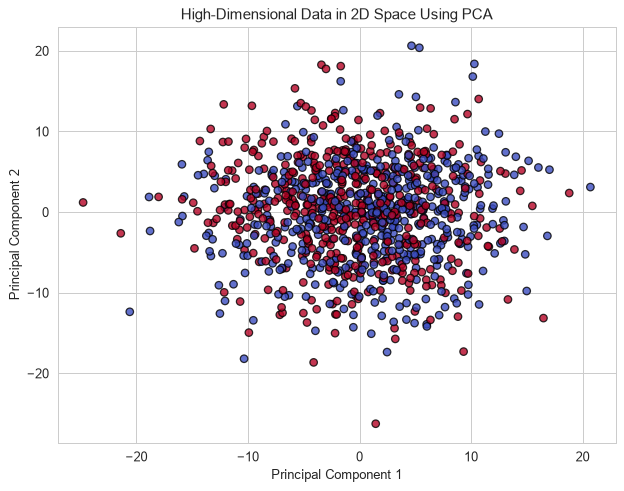

In [16]:
# Proyeksi PCA 2 dimensi untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print('Explained variance ratio PC1, PC2:', pca.explained_variance_ratio_.round(4))

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors='k', marker='o', cmap='coolwarm', alpha=0.8)
plt.title("High-Dimensional Data in 2D Space Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

**Interpretasi:**

- Dua komponen utama hanya menjelaskan **2.45% dan 2.12%** variansi total. Dengan 1000 fitur yang semuanya bervarians ~1, tidak ada arah yang dominan sehingga proyeksi 2D membuang hampir 95% informasi.
- Titik kelas 0 (biru) dan kelas 1 (merah) **bercampur total** di plot. Ini tidak berarti kelas tidak dapat dipisahkan (SVM RBF mencapai 0.85–0.96): PCA tidak melihat label, dan pemisah kelas tersebar di 50 dimensi informatif yang tidak sejajar dengan dua PC pertama.
- PCA berguna untuk eksplorasi kasar, tetapi visualisasi 2D dari data berdimensi tinggi bisa sangat menyesatkan. Metode terawasi (mis. LDA) atau non-linear (t-SNE/UMAP) dapat memberi gambaran berbeda.

## 7.5 Evaluasi Model SVM

**Teori:**

**Confusion matrix dan metrik turunannya.** Untuk kelas positif tertentu, hitung TP, FP, TN, FN. Maka

$$
\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
\text{Precision}=\frac{TP}{TP+FP},\quad
\text{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} .
$$

*Precision* menjawab "dari yang diprediksi positif, berapa yang benar?", *recall* menjawab "dari yang benar-benar positif, berapa yang tertangkap?". `classification_report` menampilkan metrik ini **per kelas**, ditambah *macro average* (rata-rata sederhana antar-kelas) dan *weighted average* (dibobot `support`). Pada data medis seperti Breast Cancer Wisconsin (target 0 = *malignant*, 1 = *benign*), recall kelas *malignant* biasanya paling penting karena FN (tumor ganas yang lolos) jauh lebih mahal.

**ROC dan AUC.** Classifier yang mengeluarkan skor $s(\mathbf x)$ dapat diubah ambangnya $t$. Kurva ROC memplot $\text{TPR}(t)=\text{Recall}$ terhadap $\text{FPR}(t)=FP/(FP+TN)$ untuk semua $t$. Garis diagonal = tebakan acak. **AUC** (luas di bawah kurva) sama dengan peluang bahwa sebuah sampel positif acak memperoleh skor lebih tinggi daripada sampel negatif acak:

$$
\text{AUC} = P\bigl(s(\mathbf x^+) > s(\mathbf x^-)\bigr).
$$

Karena hanya urutan skor yang penting, ROC/AUC dapat dihitung dari `decision_function` (jarak bertanda ke hyperplane) maupun dari probabilitas.

**Probabilitas pada SVM.** SVM tidak menghasilkan probabilitas secara alami. Buku memakai `SVC(probability=True)`, yang di balik layar menjalankan **Platt scaling**: memasang sigmoid $P(y=1\mid s)=1/(1+\exp(As+B))$ pada skor keputusan dengan CV internal 5-fold. Di scikit-learn 1.9 parameter `probability` **sudah deprecated** (akan dihapus di 1.11) dan diganti `CalibratedClassifierCV(SVC(), ensemble=False)`, yang melakukan hal setara (default `method='sigmoid'` = Platt). Notebook ini memakai pengganti tersebut. Catatan: probabilitas Platt bisa sedikit tidak konsisten dengan `predict` (yang memakai tanda skor), dan ambang 0.5 belum tentu sama dengan skor 0.

**Pentingnya scaling.** Fitur Breast Cancer memiliki skala sangat berbeda (mis. `mean area` ratusan–ribuan, `mean smoothness` sekitar 0.1). Tanpa standardisasi, kernel linear didominasi fitur berskala besar dan solver *libsvm* lambat konvergen. Sel tambahan di bawah membandingkan versi dengan `StandardScaler` dalam `Pipeline`.

In [17]:
# Memuat dataset Breast Cancer Wisconsin
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Kelas:', dict(zip(data.target_names, np.bincount(y))))
print('Rentang skala fitur: min std =', df[feature_names].std().min().round(4),
      '| max std =', df[feature_names].std().max().round(1))

Kelas: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Rentang skala fitur: min std = 0.0026 | max std = 569.4


In [18]:
# SVM linear + kalibrasi probabilitas (pengganti SVC(probability=True) yang deprecated di sklearn 1.9)
t0 = time.time()
svm_model = CalibratedClassifierCV(SVC(kernel='linear'), ensemble=False)
svm_model.fit(X_train, y_train)
print(f'Waktu latih: {time.time() - t0:.1f} detik')

y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

# Catatan: notebook resmi mencetak variabel `accuracy` dari resep sebelumnya; di sini dihitung ulang
accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True,
                                               target_names=data.target_names)).transpose()
print(f"Accuracy: {accuracy:.2f}")
display(style_report(report_df))
print('Confusion matrix (baris = aktual, kolom = prediksi; urutan malignant, benign):')
print(confusion_matrix(y_test, y_pred))

Waktu latih: 15.1 detik
Accuracy: 0.95


,precision,recall,f1-score,support
malignant,0.926,0.940,0.933,67
benign,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


Confusion matrix (baris = aktual, kolom = prediksi; urutan malignant, benign):
[[63  4]
 [ 5 99]]


**Interpretasi:**

- Dataset berisi 212 *malignant* dan 357 *benign*. Simpangan baku fitur berkisar dari **0.0026** hingga **569.4**, perbedaan skala lebih dari lima orde besaran.
- SVM linear (dengan kalibrasi Platt) memperoleh **akurasi 0.95** (162/171 benar). Untuk *malignant*: precision 0.926, recall **0.940**. Dari *confusion matrix*, **4 tumor ganas lolos** diprediksi jinak (FN, kesalahan paling berbahaya) dan 5 tumor jinak dicurigai ganas (FP).
- Waktu latih ~**10–15 detik** (bervariasi antar-eksekusi) untuk hanya 398 sampel, sangat lambat untuk ukuran data ini. Penyebabnya adalah fitur tak terskala yang membuat solver *libsvm* sulit konvergen, ditambah `CalibratedClassifierCV` yang melatih 5 model CV + 1 model akhir.
- Perbedaan dari buku: (1) `SVC(probability=True)` diganti `CalibratedClassifierCV(SVC(kernel='linear'), ensemble=False)` karena `probability` deprecated di scikit-learn 1.9; (2) buku mencetak `accuracy` dari resep 7.4 (bug), di sini akurasi dihitung ulang; (3) nama kelas ditampilkan pada laporan.

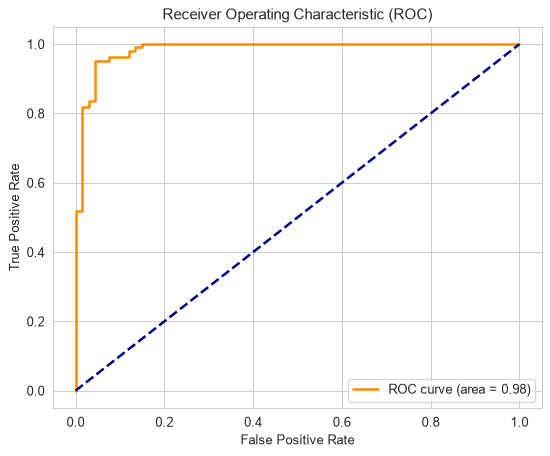

AUC = 0.9841


In [19]:
# Kurva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5.5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()
print(f'AUC = {roc_auc:.4f}')

In [20]:
# Tambahan: pengaruh standardisasi fitur (Pipeline mencegah data leakage)
t0 = time.time()
svm_scaled = make_pipeline(StandardScaler(), SVC(kernel='linear'))
svm_scaled.fit(X_train, y_train)
t_fit = time.time() - t0

y_pred_s = svm_scaled.predict(X_test)
score_s = svm_scaled.decision_function(X_test)   # ROC cukup dengan skor keputusan
fpr_s, tpr_s, _ = roc_curve(y_test, score_s)

print(f'Waktu latih (scaled): {t_fit:.2f} detik')
print(f'Accuracy (scaled)   : {accuracy_score(y_test, y_pred_s):.4f}  vs tanpa scaling: {accuracy:.4f}')
print(f'AUC (scaled)        : {auc(fpr_s, tpr_s):.4f}  vs tanpa scaling: {roc_auc:.4f}')
print('Confusion matrix (scaled):')
print(confusion_matrix(y_test, y_pred_s))

Waktu latih (scaled): 0.01 detik
Accuracy (scaled)   : 0.9825  vs tanpa scaling: 0.9474
AUC (scaled)        : 0.9989  vs tanpa scaling: 0.9841
Confusion matrix (scaled):
[[ 67   0]
 [  3 101]]


**Interpretasi:**

- Kurva ROC naik tajam ke TPR ≈ 0.95 pada FPR < 0.05 dan mencapai TPR = 1 di sekitar FPR ≈ 0.15. **AUC = 0.984**, artinya dalam 98.4% pasangan (benign, malignant) acak, sampel *benign* (kelas positif = 1) mendapat probabilitas lebih tinggi. Model memiliki daya pembeda yang sangat baik meskipun akurasi pada ambang 0.5 hanya 0.95. Menggeser ambang dapat menukar FP dengan FN sesuai kebutuhan klinis.
- Menambahkan `StandardScaler` dalam `Pipeline` mengubah hasil secara drastis:
  - waktu latih turun dari ~10–15 detik menjadi **0.01 detik**;
  - akurasi naik dari 0.947 menjadi **0.982**;
  - AUC naik dari 0.984 menjadi **0.999**;
  - **tidak ada lagi tumor ganas yang lolos** (67/67 *malignant* terdeteksi), hanya 3 *benign* yang salah diklasifikasi.
- Ini mempertegas teori: SVM berbasis jarak/margin sehingga scaling fitur hampir selalu wajib. ROC untuk model terskala dihitung dari `decision_function`, karena AUC hanya bergantung pada urutan skor dan tidak memerlukan probabilitas.

## Latihan: Practical Exercises with SVMs

Bagian ini mereproduksi solusi resmi (*Exercise Solutions*) untuk tiga latihan di akhir chapter: membangun classifier SVM sederhana, *tuning* dengan grid search, dan memvisualisasikan batas keputusan. Ketiganya menggabungkan konsep dari resep 7.1–7.5.

### Exercise 1: Membangun Classifier SVM Sederhana (Iris)

**Teori:**

Alur kerja standar scikit-learn: muat data → `train_test_split` → buat estimator → `fit` → `predict` → evaluasi. Latihan ini identik dengan resep 7.1 (SVC kernel linear pada Iris), tetapi laporan dicetak sebagai teks biasa (`classification_report` tanpa `output_dict`). Pada Iris, kelas *setosa* terpisah secara linear dari dua kelas lain, sedangkan *versicolor* dan *virginica* sedikit tumpang tindih pada ruang fitur; di sanalah kesalahan klasifikasi biasanya terjadi.

In [21]:
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.93
Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.91      0.83      0.87        12
   virginica       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.92      0.92        45
weighted avg       0.93      0.93      0.93        45

Confusion matrix:
[[18  0  0]
 [ 0 10  2]
 [ 0  1 14]]


**Interpretasi:**

- Hasilnya identik dengan resep 7.1: akurasi **0.93**, *setosa* sempurna (18/18), *versicolor* 10/12, *virginica* 14/15.
- *Confusion matrix* menunjukkan arah kesalahan: 2 *versicolor* diprediksi *virginica* dan 1 *virginica* diprediksi *versicolor*. Tidak ada kebingungan yang melibatkan *setosa*, sesuai dengan struktur data Iris.

### Exercise 2: Tuning Parameter SVM dengan Grid Search (Breast Cancer)

**Teori:**

Grid yang sama dengan resep 7.3 (27 kombinasi × 5 fold = 135 fit) diterapkan pada Breast Cancer **tanpa scaling**, persis seperti solusi resmi. Kernel linear pada data tak terskala jauh lebih lambat konvergen (beberapa detik per fit), sedangkan RBF/poly dengan `gamma='scale'` cepat tetapi cenderung kalah karena jarak Euclidean didominasi fitur berskala besar (`mean area`, `worst area`). Agar waktu eksekusi wajar, notebook ini menambahkan `n_jobs=-1` (paralel di semua core CPU), yang tidak mengubah hasil. Sebagai pembanding, grid yang sama juga dijalankan dalam `Pipeline(StandardScaler, SVC)`, di mana nama parameter diberi awalan nama langkah (`svc__C`).

In [22]:
data = load_breast_cancer()
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

t0 = time.time()
grid_search = GridSearchCV(SVC(), param_grid, cv=5, n_jobs=-1)   # n_jobs=-1 hanya untuk mempercepat
grid_search.fit(X_train, y_train)
print(f'Waktu grid search: {time.time() - t0:.1f} detik')
print('Best params:', grid_search.best_params_, f'| best CV score: {grid_search.best_score_:.4f}')

best_model = SVC(**grid_search.best_params_)
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

accuracy_best = accuracy_score(y_test, y_pred_best)
print(f"Best Model Accuracy: {accuracy_best:.2f}")
print("Best Model Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=data.target_names))

# Skor CV rata-rata per kernel & C (degree hanya relevan untuk poly)
cv_res = pd.DataFrame(grid_search.cv_results_)
display(cv_res.pivot_table(index='param_kernel', columns='param_C',
                           values='mean_test_score', aggfunc='max').round(4))

Waktu grid search: 49.5 detik
Best params: {'C': 1, 'degree': 2, 'kernel': 'linear'} | best CV score: 0.9623


Best Model Accuracy: 0.95
Best Model Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.94      0.93        67
      benign       0.96      0.95      0.96       104

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



param_C,0.1,1.0,10.0
param_kernel,,,
linear,0.9573,0.9623,0.9548
poly,0.8768,0.9044,0.9246
rbf,0.8818,0.9044,0.9221


In [23]:
# Pembanding: grid yang sama tetapi dengan StandardScaler di dalam Pipeline
pipe = make_pipeline(StandardScaler(), SVC())
param_grid_pipe = {'svc__C': [0.1, 1, 10],
                   'svc__kernel': ['linear', 'rbf', 'poly'],
                   'svc__degree': [2, 3, 4]}
grid_pipe = GridSearchCV(pipe, param_grid_pipe, cv=5, n_jobs=-1).fit(X_train, y_train)
print('Best params (scaled):', grid_pipe.best_params_, f'| best CV score: {grid_pipe.best_score_:.4f}')
print(f'Test accuracy (scaled): {grid_pipe.score(X_test, y_test):.4f}')

Best params (scaled): {'svc__C': 0.1, 'svc__degree': 2, 'svc__kernel': 'linear'} | best CV score: 0.9774
Test accuracy (scaled): 0.9825


**Interpretasi:**

- Tanpa scaling, grid search (135 fit, ~**48 detik** dengan `n_jobs=-1`) memilih **kernel linear, $C=1$** dengan skor CV **0.9623** (`degree`=2 hanya karena urutan grid, sebab nilainya diabaikan kernel linear). Akurasi ujinya **0.95**, dengan recall *malignant* 0.94.
- Tabel pivot memperlihatkan kernel linear unggul jelas pada data tak terskala (0.955–0.962), sedangkan RBF dan poly hanya 0.877–0.925. Jarak Euclidean pada RBF/poly didominasi fitur berskala ratusan–ribuan (`area`), sehingga kernel non-linear praktis hanya "melihat" segelintir fitur. Untuk RBF/poly, $C$ lebih besar selalu lebih baik, tanda bahwa model masih *underfit*.
- Dengan `StandardScaler` di dalam `Pipeline`, kombinasi terbaik menjadi **linear, $C=0.1$** dengan skor CV **0.9774** dan akurasi uji **0.9825**, naik sekitar 3 poin dan jauh lebih cepat dilatih. Grid search tidak dapat menggantikan *preprocessing* yang benar.

### Exercise 3: Visualisasi Decision Boundary SVM (data sintetis 2D)

**Teori:**

Dengan hanya dua fitur, batas keputusan dapat digambar langsung: buat *mesh grid* yang menutupi ruang fitur, prediksi kelas setiap titik grid, lalu warnai dengan `contourf`. `make_classification(n_features=2, n_informative=2, n_redundant=0)` membangkitkan tiap kelas dari *cluster* Gaussian (default `n_clusters_per_class=2`), sehingga tiap kelas bisa terdiri dari dua gumpalan dan batas optimalnya tidak harus lurus. Kernel RBF fleksibel untuk bentuk seperti ini. Selain kelas prediksi, nilai `decision_function` juga dapat digambar: kontur 0 adalah batas keputusan, kontur $\pm1$ adalah tepi margin, dan titik yang dilingkari adalah support vectors.

Akurasi uji: 0.9767 | jumlah support vector: 118


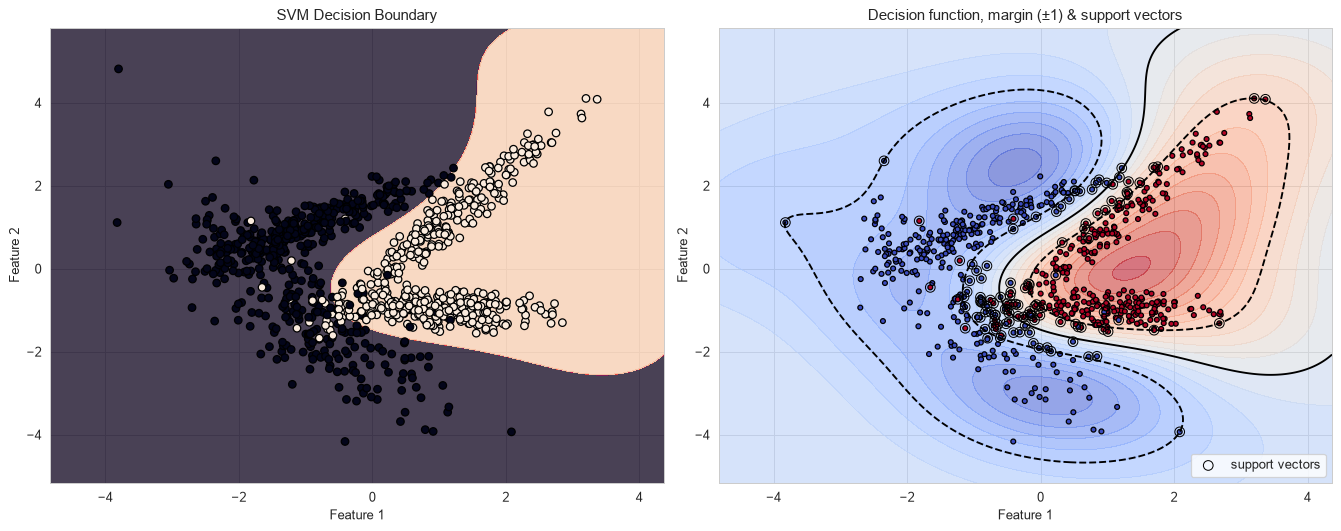

In [24]:
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2,
                           n_redundant=0, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

svm_model = SVC(kernel='rbf')
svm_model.fit(X_train, y_train)
print(f'Akurasi uji: {svm_model.score(X_test, y_test):.4f} | jumlah support vector: {svm_model.n_support_.sum()}')

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))
grid = np.c_[xx.ravel(), yy.ravel()]

Z = svm_model.predict(grid).reshape(xx.shape)
D = svm_model.decision_function(grid).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
# Kiri: plot asli dari solusi resmi (kelas prediksi)
axes[0].contourf(xx, yy, Z, alpha=0.8)
axes[0].scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
axes[0].set_title("SVM Decision Boundary")
# Kanan: tambahan, decision function + margin + support vectors (data latih)
axes[1].contourf(xx, yy, D, levels=20, cmap='coolwarm', alpha=0.6)
axes[1].contour(xx, yy, D, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'])
axes[1].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', s=15)
sv = svm_model.support_vectors_
axes[1].scatter(sv[:, 0], sv[:, 1], s=60, facecolors='none', edgecolors='k', linewidths=0.8,
                label='support vectors')
axes[1].set_title("Decision function, margin (±1) & support vectors")
axes[1].legend(loc='lower right')
for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

**Interpretasi:**

- SVM RBF mencapai akurasi uji **0.977** dengan **118 support vector** dari 700 titik latih (17%). Hanya titik di sekitar zona tumpang tindih yang menentukan batas.
- **Plot kiri** (versi solusi resmi): kelas 1 (putih) membentuk dua "lengan", yaitu dua *cluster* per kelas dari `make_classification`, dan RBF membentuk batas melengkung yang membungkus keduanya. Garis lurus tidak akan mampu memisahkan bentuk ini dengan baik.
- **Plot kanan** (tambahan): garis hitam tegas adalah $f(\mathbf x)=0$ (batas keputusan), garis putus-putus adalah tepi margin $f(\mathbf x)=\pm1$. Titik yang dilingkari (support vectors) berada di dalam margin, di tepinya, atau di sisi yang salah. Titik jauh dari batas tidak ikut menentukan model. Warna gradasi menunjukkan besarnya skor: makin jauh dari batas, makin yakin model.
- Di area tanpa data (mis. kanan bawah), batas mengikuti bentuk kernel yang meluruh dan keputusan di sana bersifat ekstrapolasi yang tidak dapat diandalkan.

## Ringkasan Chapter 7

1. **SVM = classifier margin maksimum.** SVM mencari hyperplane $\mathbf w^\top\mathbf x+b=0$ yang memaksimalkan margin $2/\lVert\mathbf w\rVert$. *Soft margin* dengan parameter $C$ setara dengan meminimalkan *hinge loss* + regularisasi L2. Solusinya hanya bergantung pada **support vectors**: pada Iris, cukup 21 dari 105 titik untuk SVC linear dengan akurasi uji 0.93.
2. **SVR** memakai $\varepsilon$-insensitive loss (tabung selebar $2\varepsilon$). Contoh buku (SVR untuk label Iris dengan dua fitur sepal) menghasilkan MSE 0.20 / $R^2$ 0.72, namun untuk target kategorikal `SVC` adalah pilihan yang tepat.
3. **Kernel trick** mengganti hasil kali dalam dengan $K(\mathbf x,\mathbf x')$ (linear, polinomial, RBF, sigmoid), sehingga batas non-linear diperoleh tanpa membentuk fitur berdimensi tinggi. Pada Iris, perbedaan antar-kernel hanya 1–2 sampel uji (0.91–0.96), dan dengan dua fitur sepal ketiganya mentok di ~0.80 karena kelas memang tumpang tindih.
4. **Tuning** `C`, `kernel`, `degree` (dan `gamma`) dilakukan dengan `GridSearchCV` dalam skala log. Kurva $C$ pada Iris menunjukkan *underfitting* (0.36 untuk $C\le0.006$), optimum 0.99 di $C\approx2.8$, lalu turun perlahan. Banyak kombinasi seri sehingga "parameter terbaik" bisa ditentukan oleh urutan grid, dan skor CV terbaik cenderung optimistis.
5. **Data berdimensi tinggi**: SVM tetap dapat dilatih saat $p>n$, tetapi akurasi latih 100% menipu (uji 0.75 pada 1000 fitur dengan 950 noise). Membuang fitur noise dan memakai kernel yang sesuai struktur sinyal (RBF 0.957 dengan 50 fitur informatif) jauh lebih menentukan. PCA 2D (variansi ~4.6%) tidak memperlihatkan pemisahan kelas.
6. **Evaluasi** memakai precision, recall, F1, *confusion matrix*, ROC/AUC. Di scikit-learn 1.9 `SVC(probability=True)` deprecated, sehingga dipakai `CalibratedClassifierCV(..., ensemble=False)` (Platt scaling) atau langsung `decision_function` untuk ROC. Pada Breast Cancer, **scaling fitur** menaikkan akurasi 0.947 → 0.982, AUC 0.984 → 0.999, menghapus semua FN *malignant*, dan mempercepat pelatihan ~1000×.
7. **Latihan** menegaskan pola yang sama: grid search tanpa scaling memilih kernel linear (uji 0.95), sedangkan dengan `Pipeline(StandardScaler, SVC)` mencapai 0.982. Visualisasi `decision_function` menampilkan batas, margin ±1, dan support vectors (118/700) secara langsung.